# 03 · Hyperparameter Tuning & Evaluation
**Owner:** Member 3

Tune with Keras Tuner, pick the best model, evaluate on the test set, and **save `best_model.keras`**.

In [1]:
# ===== SHARED SETUP (same in every notebook — don't change without telling the team) =====
import os, sys

# In Colab: clone the repo and move into it
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/<OWNER>/insurance-risk-scoring.git"  # <-- set once
    if not os.path.exists("insurance-risk-scoring"):
        !git clone {REPO_URL}
    %cd insurance-risk-scoring
elif os.path.basename(os.getcwd()) == "dev":
    os.chdir("../..")  # running locally from notebooks/dev

import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Paths
RAW_CSV          = "data/raw/Car_Insurance_Claim.csv"
PROCESSED_DIR    = "data/processed"
MODELS_DIR       = "models"
FIGURES_DIR      = "reports/figures"
PREPROCESSOR_PKL = f"{MODELS_DIR}/preprocessor.pkl"
BEST_MODEL       = f"{MODELS_DIR}/best_model.keras"
TARGET           = "OUTCOME"

def load_splits():
    """Load the frozen splits saved by notebook 01."""
    names = ["X_train", "X_val", "X_test", "y_train", "y_val", "y_test"]
    return [np.load(f"{PROCESSED_DIR}/{n}.npy") for n in names]


## 1. Load Splits

In [2]:

import json
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras import layers, regularizers

import keras_tuner as kt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

# Load the frozen datasets from Member 1
X_train, X_val, X_test, y_train, y_val, y_test = load_splits()

# Load class weights
with open(f"{PROCESSED_DIR}/class_weights.json") as f:
    CLASS_WEIGHT = {int(k): float(v) for k, v in json.load(f).items()}

# Load Member 2's regularized model configuration
with open(f"{MODELS_DIR}/regularized_config.json") as f:
    REG_CONFIG = json.load(f)

N_FEATURES = X_train.shape[1]

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

print("\nNumber of features:", N_FEATURES)
print("Class weights:", CLASS_WEIGHT)
print("Starting configuration:", REG_CONFIG)


Training data: (5703, 23)
Validation data: (1223, 23)
Testing data: (1223, 23)

Number of features: 23
Class weights: {0: 0.7257571901247136, 1: 1.6073844419391206}
Starting configuration: {'units': [64, 32], 'l2': 0.001, 'dropout': 0.3, 'learning_rate': 0.001, 'batch_size': 32, 'early_stopping': {'monitor': 'val_loss', 'patience': 15}, 'best_epoch': 41}


## 2. Define `build_model(hp)`

In [4]:

def build_model(hp):

    model = keras.Sequential(name="tuned_ann")

    model.add(keras.Input(shape=(N_FEATURES,)))

    # First hidden layer
    units_1 = hp.Choice(
        "units_1",
        values=[32, 64, 128]
    )

    model.add(
        layers.Dense(
            units_1,
            activation="relu",
            kernel_regularizer=regularizers.l2(
                hp.Choice("l2", values=[0.0001, 0.001, 0.01])
            )
        )
    )

    # Second hidden layer
    units_2 = hp.Choice(
        "units_2",
        values=[16, 32, 64]
    )

    model.add(
        layers.Dense(
            units_2,
            activation="relu",
            kernel_regularizer=regularizers.l2(
                hp.get("l2")
            )
        )
    )

    # Dropout
    dropout = hp.Choice(
        "dropout",
        values=[0.2, 0.3, 0.4]
    )

    model.add(layers.Dropout(dropout))

    # Output layer
    model.add(layers.Dense(1, activation="sigmoid"))

    # Learning rate
    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.0001, 0.001, 0.01]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall")
        ]
    )

    return model


## 3. Keras Tuner Search

In [6]:
import sys
!{sys.executable} -m pip install tensorboard
# Create the tuner
tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective=kt.Objective("val_auc", direction="max"),
    max_trials=20,
    executions_per_trial=1,
    directory="tuning_results",
    project_name="insurance_risk_tuning",
    overwrite=True,
    seed=SEED
)

# Early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Start hyperparameter search
tuner.search(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    class_weight=CLASS_WEIGHT,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("Hyperparameter search completed!")


Trial 20 Complete [00h 00m 22s]
val_auc: 0.9363517165184021

Best val_auc So Far: 0.938920259475708
Total elapsed time: 00h 13m 03s
Hyperparameter search completed!


## 4. Train Best Model

In [7]:

# Get the best hyperparameters
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best Hyperparameters:\n")

for key, value in best_hp.values.items():
    print(f"{key}: {value}")


# Get the best trained model
best_model = tuner.get_best_models(num_models=1)[0]


# Display model architecture
print("\nBest Model Architecture:")
best_model.summary()


# Get the best trial results
best_trial = tuner.oracle.get_best_trials(num_trials=1)[0]

print("\nBest Trial Results:")
print("Best Validation AUC:", best_trial.score)

print("\nBest model successfully loaded!")


Best Hyperparameters:

units_1: 32
l2: 0.01
units_2: 64
dropout: 0.4
learning_rate: 0.01

Best Model Architecture:


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


Model: "tuned_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)


Best Trial Results:
Best Validation AUC: 0.938920259475708

Best model successfully loaded!


## 5. Test Evaluation (Precision, Recall, F1, ROC-AUC)

In [8]:

# Make predictions on the test dataset
y_prob = best_model.predict(
    X_test,
    verbose=0
).ravel()

# Convert probabilities into class predictions
y_pred = (y_prob >= 0.5).astype(int)


# Calculate evaluation metrics
test_results = {
    "Accuracy": accuracy_score(y_test, y_pred),

    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),

    "Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),

    "F1-Score": f1_score(
        y_test, y_pred, zero_division=0
    ),

    "ROC-AUC": roc_auc_score(y_test, y_prob)
}


# Display final evaluation results
print("Final Test Evaluation Results")
print("=" * 40)

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")


# Classification Report
print("\nClassification Report")
print("=" * 40)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Claim", "Claim"],
        zero_division=0
    )
)


Final Test Evaluation Results
Accuracy: 0.8201 (82.01%)
Precision: 0.6695 (66.95%)
Recall: 0.8346 (83.46%)
F1-Score: 0.7430 (74.30%)
ROC-AUC: 0.9027 (90.27%)

Classification Report
              precision    recall  f1-score   support

    No Claim       0.92      0.81      0.86       842
       Claim       0.67      0.83      0.74       381

    accuracy                           0.82      1223
   macro avg       0.79      0.82      0.80      1223
weighted avg       0.84      0.82      0.82      1223



## 6. Confusion Matrix & ROC Curve

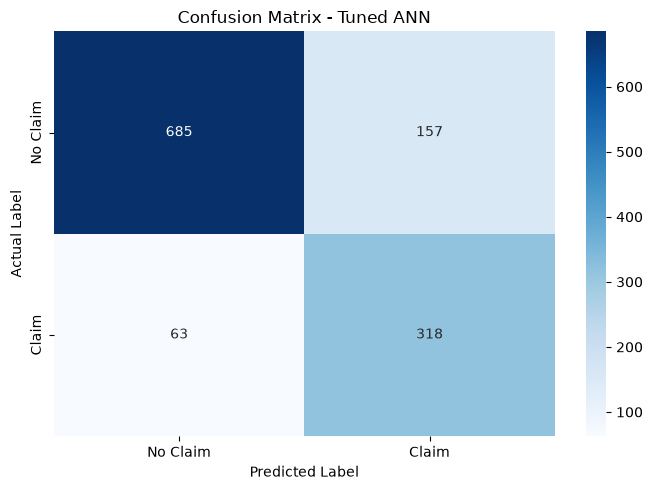

<Figure size 700x500 with 0 Axes>

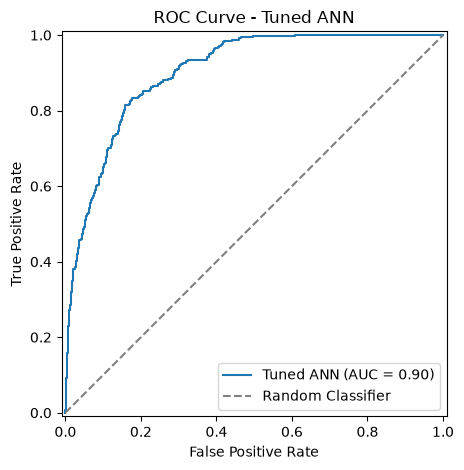

Confusion Matrix and ROC Curve generated successfully!


In [9]:
# Create figures directory if it does not exist
os.makedirs(FIGURES_DIR, exist_ok=True)


# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Claim", "Claim"],
    yticklabels=["No Claim", "Claim"]
)

plt.title("Confusion Matrix - Tuned ANN")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

# Save confusion matrix
plt.savefig(
    f"{FIGURES_DIR}/10_tuned_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 2. ROC Curve
plt.figure(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Tuned ANN"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curve - Tuned ANN")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()

# Save ROC curve
plt.savefig(
    f"{FIGURES_DIR}/11_tuned_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix and ROC Curve generated successfully!")

## 7. Error Analysis & Limitations

In [10]:
# 1. Identify incorrect predictions

errors = y_test != y_pred

false_positives = (y_test == 0) & (y_pred == 1)
false_negatives = (y_test == 1) & (y_pred == 0)

correct_predictions = (y_test == y_pred)

print("Error Analysis")
print("=" * 40)

print(f"Total Test Samples: {len(y_test)}")
print(f"Correct Predictions: {correct_predictions.sum()}")
print(f"Total Errors: {errors.sum()}")

print(f"\nFalse Positives: {false_positives.sum()}")
print(f"False Negatives: {false_negatives.sum()}")

print(
    f"\nError Rate: {errors.mean() * 100:.2f}%"
)


# 2. Calculate error percentages

print("\nError Percentages")
print("=" * 40)

print(
    f"False Positive Rate: "
    f"{false_positives.sum() / (y_test == 0).sum() * 100:.2f}%"
)

print(
    f"False Negative Rate: "
    f"{false_negatives.sum() / (y_test == 1).sum() * 100:.2f}%"
)


# 3. Display sample incorrect predictions

error_indices = np.where(errors)[0]

error_analysis = pd.DataFrame({
    "Actual": y_test[error_indices],
    "Predicted": y_pred[error_indices],
    "Predicted Probability": y_prob[error_indices]
})

error_analysis["Actual"] = error_analysis["Actual"].map({
    0: "No Claim",
    1: "Claim"
})

error_analysis["Predicted"] = error_analysis["Predicted"].map({
    0: "No Claim",
    1: "Claim"
})

print("\nSample Incorrect Predictions")
print("=" * 40)

display(error_analysis.head(10))

Error Analysis
Total Test Samples: 1223
Correct Predictions: 1003
Total Errors: 220

False Positives: 157
False Negatives: 63

Error Rate: 17.99%

Error Percentages
False Positive Rate: 18.65%
False Negative Rate: 16.54%

Sample Incorrect Predictions


,Actual,Predicted,Predicted Probability
0,No Claim,Claim,0.629759
1,Claim,No Claim,0.319011
2,No Claim,Claim,0.890732
3,Claim,No Claim,0.453113
4,No Claim,Claim,0.501923
5,Claim,No Claim,0.364040
6,Claim,No Claim,0.341975
7,No Claim,Claim,0.683162
8,Claim,No Claim,0.208866
9,No Claim,Claim,0.859490


## 8. Save `models/best_model.keras`

In [11]:
# 1. Create required directories
os.makedirs(MODELS_DIR, exist_ok=True)


# 2. Save the best model
best_model.save(BEST_MODEL)

print("Best model saved successfully!")
print(f"Model location: {BEST_MODEL}")


# 3. Save best hyperparameters
best_hyperparameters = best_hp.values

with open(
    f"{MODELS_DIR}/best_hyperparameters.json",
    "w"
) as f:
    json.dump(best_hyperparameters, f, indent=4)


print("\nBest hyperparameters saved successfully!")


# 4. Save test evaluation results
with open(
    f"{MODELS_DIR}/test_evaluation_results.json",
    "w"
) as f:
    json.dump(test_results, f, indent=4)


print("\nTest evaluation results saved successfully!")


# 5. Verify saved files
print("\nSaved Files")
print("=" * 40)

print("Best Model:", os.path.exists(BEST_MODEL))

print(
    "Hyperparameters:",
    os.path.exists(f"{MODELS_DIR}/best_hyperparameters.json")
)

print(
    "Evaluation Results:",
    os.path.exists(f"{MODELS_DIR}/test_evaluation_results.json")
)

Best model saved successfully!
Model location: models/best_model.keras

Best hyperparameters saved successfully!

Test evaluation results saved successfully!

Saved Files
Best Model: True
Hyperparameters: True
Evaluation Results: True
